# **E-Commerce Data: Statistical Modelling Focus**
Typically e-commerce datasets are proprietary and consequently hard to find among publicly available data. However, The UCI Machine Learning Repository has made this dataset containing actual transactions from 2010 and 2011. The dataset is maintained on their site, where it can be found by the title "Online Retail".

This is a transnational data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.The company mainly sells unique all-occasion gifts. Many customers of the company are wholesalers.

**Dataset Contents :**
- Invoice Number
- Stock Code
- Description
- Quantity
- Invoice Date
- Unit Price
- Customer ID
- Country of Customer

### **Statistical Modelling Applications**
**Revenue Concentration Rate** : We compute the aggregate revenue concentration by ranking all unique customers in descending order of their total net monetary value and calculating the cumulative share generated exclusively by the top ten percent of buyers. This single summary statistic effectively frames every downstream customer segment by exposing the heavy-tailed nature of the retail transaction distribution

**Monthly Cohort Retention Chart** : We construct a monthly cohort retention grid to picture the longitudinal dynamics of repeat purchasing behavior across the 2010 through 2011 trading period. Each cohort is defined by the calendar month of a customer's first recorded transaction, and subsequent cells track the percentage of those users who successfully place another order in later months. The resulting statistical grid must align directly with our RFM segmentation outputs so that high-value customer tiers correspond to cohorts displaying sustained multi-period retention


In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
from matplotlib import pyplot as plt

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/carrie1/ecommerce-data/data.csv


In [2]:
data = pd.read_csv('/kaggle/input/datasets/carrie1/ecommerce-data/data.csv', encoding='latin1')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [3]:
data.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

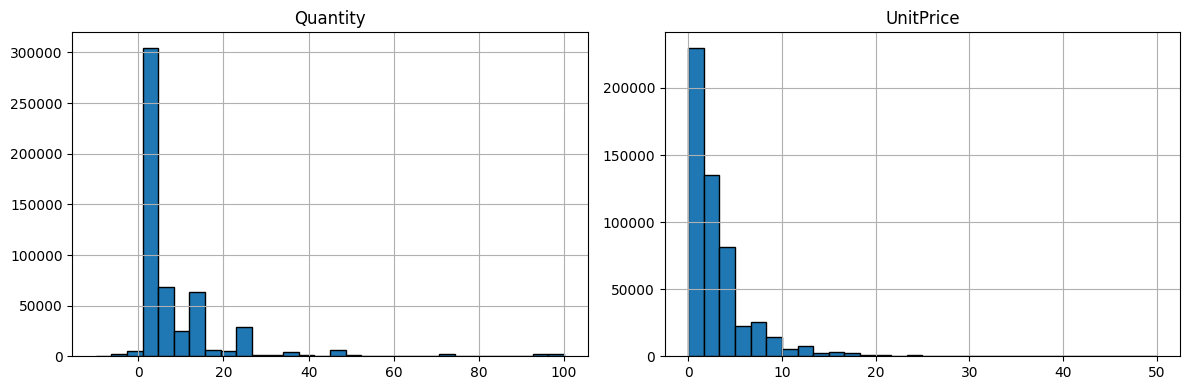

In [4]:
filtered_data = data[
    (data['Quantity'] >= -10)
    & (data['Quantity'] <= 100)
    & (data['UnitPrice'] >= 0)
    & (data['UnitPrice'] <= 50)
]

filtered_data[['Quantity', 'UnitPrice']].hist(
    bins=30, figsize=(12, 4), edgecolor='black'
)
plt.tight_layout()
plt.show()

In [5]:
data['Description'].fillna('Unknown')
data = data.dropna(subset=['CustomerID'])

In [6]:
data.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [7]:
# Revenue Concentration Rate
# compute the aggregate revenue concentration by ranking all unique customers in descending order of their 
# total net monetary value and calculating the cumulative share generated exclusively by the top ten percent of buyers

data['TotalPrice'] = data['Quantity'] * data['UnitPrice']

# Group by CustomerID and sum their total spend
customer_revenue = (
    data.groupby('CustomerID')['TotalPrice'].sum().reset_index()
)

# Sort customers in descending order of their total monetary value
customer_revenue = customer_revenue.sort_values(
    by='TotalPrice', ascending=False
).reset_index(drop=True)

# Calculate cumulative revenue and share
customer_revenue['CumulativeRevenue'] = customer_revenue['TotalPrice'].cumsum()
total_revenue = customer_revenue['TotalPrice'].sum()
customer_revenue['CumulativeShare'] = (
    customer_revenue['CumulativeRevenue'] / total_revenue
)

top_10_count = int(len(customer_revenue) * 0.10)
top_10_share = customer_revenue.loc[top_10_count - 1, 'CumulativeShare']

print(f'Total Unique Customers: {len(customer_revenue)}')
print(
    f'Revenue generated by the top 10% ({top_10_count} customers):'
    f' {top_10_share * 100:.2f}%'
)

Total Unique Customers: 4372
Revenue generated by the top 10% (437 customers): 60.01%


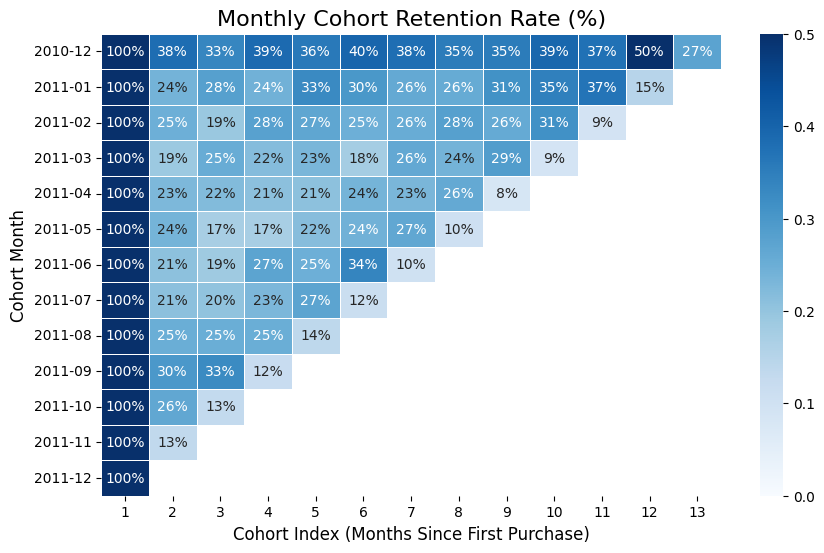

In [8]:
# Monthly Cohort Retention Chart
# construct a monthly cohort retention grid to picture the longitudinal dynamics of repeat purchasing 
# behavior across the 2010 through 2011 trading period. Each cohort is defined by the calendar month of a customer's 
# first recorded transaction, and subsequent cells track the percentage of those users who successfully place another 
# order in later months. The resulting statistical grid must align directly with our RFM segmentation outputs so that 
# high-value customer tiers correspond to cohorts displaying sustained multi-period retention

# Convert InvoiceDate to datetime and extract the month period
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])
data['InvoiceMonth'] = data['InvoiceDate'].dt.to_period('M')

# Find the cohort month (the earliest invoice month for each customer)
data['CohortMonth'] = data.groupby('CustomerID')['InvoiceMonth'].transform(
    'min'
)

# Calculate the Cohort Index (no. of months elapsed since the first purchase)
def get_month_diff(df):
  inv_y, inv_m = df['InvoiceMonth'].dt.year, df['InvoiceMonth'].dt.month
  coh_y, coh_m = df['CohortMonth'].dt.year, df['CohortMonth'].dt.month
  return (inv_y - coh_y) * 12 + (inv_m - coh_m) + 1
    
data['CohortIndex'] = get_month_diff(data)


cohort_data = (
    data.groupby(['CohortMonth', 'CohortIndex'])['CustomerID']
    .nunique()
    .reset_index()
)

# Pivot the data to build the grid matrix
cohort_matrix = cohort_data.pivot(
    index='CohortMonth', columns='CohortIndex', values='CustomerID'
)

# Calculate retention rates (divide each row by its initial month size)
cohort_sizes = cohort_matrix.iloc[:, 0]
retention_matrix = cohort_matrix.divide(cohort_sizes, axis=0)

plt.figure(figsize=(10, 6))
plt.title('Monthly Cohort Retention Rate (%)', fontsize=16)

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt='.0%',
    cmap='Blues',
    vmin=0.0,
    vmax=0.5,  # Adjust scale as needed
    linewidths=0.5,
)

plt.xlabel('Cohort Index (Months Since First Purchase)', fontsize=12)
plt.ylabel('Cohort Month', fontsize=12)
plt.yticks(rotation=0)
plt.show()